# Semi-analytical inversion with TRISHNA bands: what can be retrieved?

## Requirements
- No image needed (invRrs forward model).

## Tutorial objectives
- Simulate water reflectances from concentrations (Chl-a, CDOM, SPM) with invRrs.
- Integrate them over TRISHNA and Sentinel-2 bands.
- Map the information content (expected retrieval uncertainty) of both sensors.
- Invert noisy synthetic TRISHNA spectra.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: ~3 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
# plot style: Times-like serif fonts with LaTeX-style math (STIX, no TeX installation needed),
# larger fonts, minor ticks on all axes
plt.rcParams.update({'figure.dpi': 90, 'font.size': 14, 'font.family': 'STIXGeneral',
                     'mathtext.fontset': 'stix', 'axes.titlesize': 15, 'axes.labelsize': 15,
                     'legend.fontsize': 12, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

import invRrs.inverse as inv
from invRrs import utils as u
from trishna_tbx.inversion import trishna_forward_model, information_content

trishna_tbx 0.0.1


## 1. Forward model
`MultispectralSimple` (invRrs): Chl-a (phytoplankton absorption/backscattering), CDOM
absorption at 440 nm, SPM (Mie, normalised) and a spectrally flat offset (residual glint /
atmospheric correction error). Rrs is computed at 1 nm and integrated over each band,
weighted by the downwelling irradiance.

In [2]:
aphy, bbphy = u.data().load_iop_phyto('Bricaud1995')
SZA = 30.
models = {'TRISHNA': trishna_forward_model('MultispectralSimple', aphy_star=aphy, bbphy_star=bbphy, sza=SZA),
          'S2': inv.MultispectralSimple(aphy, bbphy, SZA, sat='s2a', band_idx=[0, 1, 2, 3, 4, 5, 6, 8])}
hyper = inv.MultispectralSimple(aphy, bbphy, SZA, wl_=np.arange(400., 901., 2.))
for n, m in models.items():
    print(n, np.round(m.wl), m.param_names)

TRISHNA [485. 555. 670. 860.] ('chl', 'a_cdom', 'spm_norm', 'offset')
S2 [443. 492. 560. 665. 704. 741. 783. 865.] ('chl', 'a_cdom', 'spm_norm', 'offset')


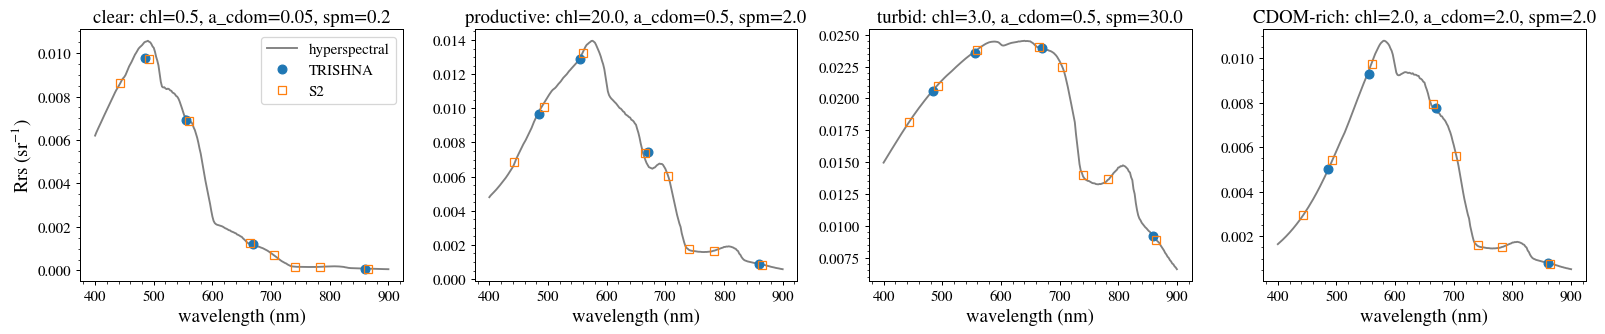

In [3]:
cases = {'clear': [0.5, 0.05, 0.2, 0.], 'productive': [20., 0.5, 2., 0.], 'turbid': [3., 0.5, 30., 0.],
         'CDOM-rich': [2., 2., 2., 0.]}
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, (n, x) in zip(axs, cases.items()):
    ax.plot(hyper.wl, hyper.forward_model(np.array(x), output='Rrs'), c='0.5', label='hyperspectral')
    for (s, m), mk in zip(models.items(), ['o', 's']):
        ax.plot(m.wl, m.forward_model(np.array(x), output='Rrs'), mk, ms=7, label=s, mfc='none' if mk == 's' else None)
    ax.set_title(f'{n}: chl={x[0]}, a_cdom={x[1]}, spm={x[2]}'); ax.set_xlabel('wavelength (nm)')
axs[0].set_ylabel('Rrs (sr$^{-1}$)'); axs[0].legend()
fig.tight_layout()
fig.savefig(THUMB_DIR / 'inversion_information_content.png', dpi=60)

## 2. Information content
Linearised (Gauss-Newton) posterior standard deviation of each unknown for an Rrs uncertainty
of 5 % + 2e-4 sr-1 per band. A relative standard deviation > 1 means the parameter is not
retrievable at this state. With 4 bands and 4 unknowns, TRISHNA is exactly determined.

In [4]:
%%time
chl = np.logspace(-1, 2, 9)
spm = np.logspace(-1, 2, 9)
A_CDOM = 0.3
out = {n: np.full((2, chl.size, spm.size), np.nan) for n in models}
for n, m in models.items():
    for i, c in enumerate(chl):
        for j, s in enumerate(spm):
            x = [c, A_CDOM, s, 0.]
            r = np.asarray(m.forward_model(np.array(x), output='Rrs'))
            ic = information_content(m, x, 0.05 * r + 2e-4)
            out[n][:, i, j] = ic['std'].values[[0, 2]] / np.array([c, s])

CPU times: user 9.27 s, sys: 25 ms, total: 9.3 s
Wall time: 9.3 s


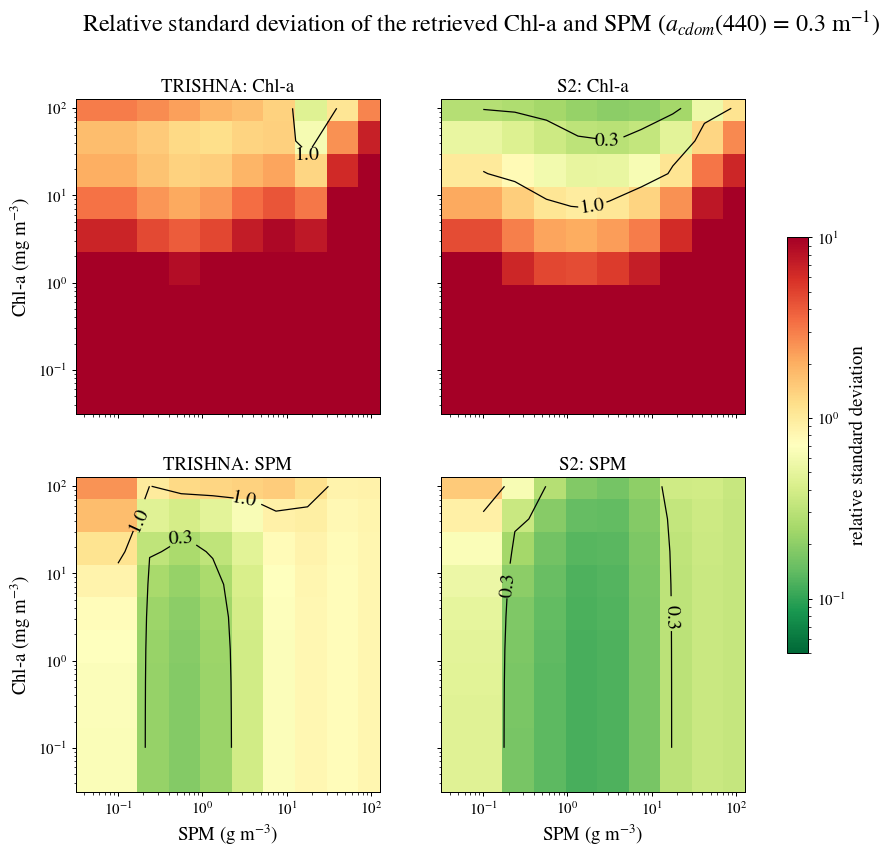

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for col, n in enumerate(models):
    for row, p in enumerate(['Chl-a', 'SPM']):
        ax = axs[row, col]
        im = ax.pcolormesh(spm, chl, out[n][row], norm=plt.matplotlib.colors.LogNorm(0.05, 10), cmap='RdYlGn_r')
        cs = ax.contour(spm, chl, out[n][row], levels=[0.3, 1.], colors='k', linewidths=1)
        ax.clabel(cs, fmt='%.1f'); ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'{n}: {p}')
for ax in axs[-1]: ax.set_xlabel('SPM (g m$^{-3}$)')
for ax in axs[:, 0]: ax.set_ylabel('Chl-a (mg m$^{-3}$)')
fig.suptitle(f'Relative standard deviation of the retrieved Chl-a and SPM ($a_{{cdom}}(440)$ = {A_CDOM} m$^{{-1}}$)')
fig.colorbar(im, ax=axs, shrink=.6, label='relative standard deviation')

## 3. Inversion of noisy synthetic spectra
Monte-Carlo: 100 noise realisations of a productive, moderately turbid case.

CPU times: user 1.71 s, sys: 2.08 ms, total: 1.71 s
Wall time: 1.71 s


TRISHNA                     S2                
         chl a_cdom spm_norm    chl a_cdom spm_norm
0.16  -100.0  -31.0    -25.0 -100.0  -17.0    -13.0
0.50   -69.0    4.0     -8.0  -25.0    3.0     -3.0
0.84    92.0   34.0      6.0   40.0   25.0      4.0

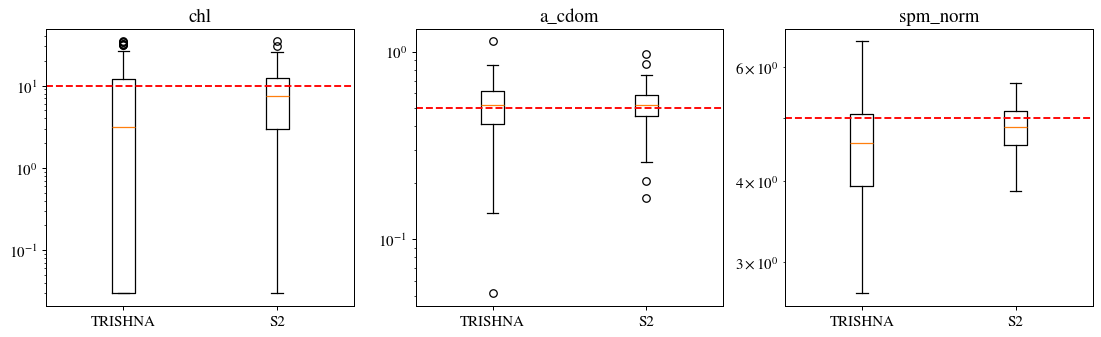

In [6]:
%%time
truth = np.array([10., 0.5, 5., 0.])
rng = np.random.default_rng(0)
res = {}
for n, m in models.items():
    r0 = np.asarray(m.forward_model(truth, output='Rrs'))
    sigma = 0.05 * r0 + 2e-4
    sols = []
    for k in range(100):
        y = r0 + sigma * rng.standard_normal(r0.size)
        sol = m.call_solver_scipy(y, sigma=sigma)
        sols.append(sol.x)
    res[n] = pd.DataFrame(sols, columns=m.param_names)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (p, t) in zip(axs, zip(['chl', 'a_cdom', 'spm_norm'], truth)):
    ax.boxplot([res[n][p] for n in models], labels=list(models)); ax.axhline(t, c='r', ls='--')
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_yscale('log'); ax.set_title(p)
pd.concat({n: (100 * (r.iloc[:, :3].quantile([0.16, 0.5, 0.84]) / truth[:3] - 1)).round(0)
           for n, r in res.items()}, axis=1)

## Take-home messages
- With TRISHNA bands, Chl-a and CDOM are strongly correlated (no 443 nm, no red edge): Chl-a
  is only weakly constrained, except at high concentrations.
- SPM remains retrievable from low to high turbidity, slightly less precisely than with S2.
- Priors are needed for Chl-a: OWT-based constraints, regional CDOM-salinity/temperature
  relationships, or the temporal information (TRISHNA revisit and thermal bands).